In [175]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time

!pip install -q k-center
from k_center import KCenter
from sklearn.datasets import (load_iris, load_diabetes, load_wine, load_breast_cancer, load_digits)

In [176]:
def eucl_distance(p1, p2):
    total = 0
    for i in range(len(p1)):
        dif = p1[i] - p2[i]
        total += dif * dif
    return total**0.5

def distance_matrix(data):
    n = len(data)
    dist = [[0 for j in range(n)] for i in range(n)]

    for i in range(n):
        for j in range(i + 1, n):
            d = eucl_distance(data[i], data[j])
            dist[i][j] = d
            dist[j][i] = d
    return dist

In [177]:
def cost_cal(dist, centers):
    n = len(dist)
    max_distance = 0
    for i in range(n):
        nearest = float('inf')
        for c in centers:
            nearest = min(nearest, dist[i][c])

        max_distance = max(max_distance, nearest)
    return max_distance

In [178]:
def greedy_kcenter(dist, k):
    start = time.perf_counter()
    n = len(dist)
    centers = [0]
    min_dist = [float('inf')] * n

    while len(centers) < k:
        last_center = centers[-1]
        for i in range(n):
            d = dist[i][last_center]
            min_dist[i] = min(min_dist[i],d)

        farthest = -1
        maximum_distance = -1

        for i in range(n):
          if min_dist[i] > maximum_distance:
            maximum_distance = min_dist[i]
            farthest = i
        centers.append(farthest)

    cost = cost_cal(dist, centers)
    end = time.perf_counter()
    execution_time = end - start
    return cost, execution_time*1000, centers

In [179]:
def heuristic(data, k):
    X = np.array(data)
    start = time.perf_counter()
    model = KCenter(n_clusters=k,distance_metric="euclidean")
    model.fit(X)
    end = time.perf_counter()
    execution_time = end - start

    centers = [int(i) for i in model.center_indices_]
    cost = float(model.objective_radius_)
    return cost, execution_time*1000, centers

Heuristic: cost: 2.23606797749979 centers: [5, 0, 6] time (s): 0.601546
Greedy   : cost: 2.23606797749979 centers: [0, 7, 3] time (s): 0.060923


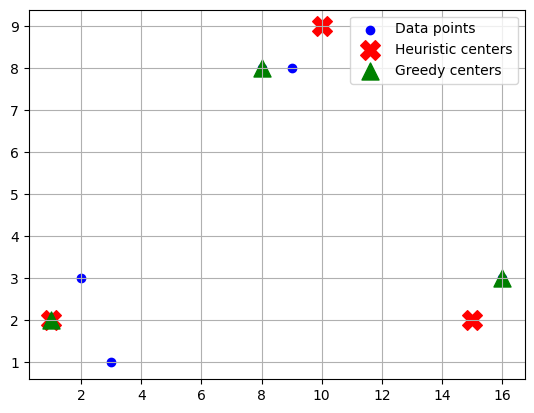

In [180]:
toy_data = [[1, 2],[2, 3],[3, 1],[8, 8],[9, 8],[10, 9],[15, 2],[16, 3]]
n = len(toy_data)
k = 3
dist = distance_matrix(toy_data)
h_cost, h_time, h_centers = heuristic(toy_data, k)
g_cost, g_time, g_centers = greedy_kcenter(dist, k)

print("Heuristic: cost:", h_cost, "centers:", h_centers,"time (s):", f'{h_time:.6f}')
print("Greedy   : cost:", g_cost,"centers:", g_centers,"time (s):", f'{g_time:.6f}')

x = [i[0] for i in toy_data]
y = [i[1] for i in toy_data]
plt.scatter(x, y, color='blue', label='Data points')

plt.scatter([x[i] for i in h_centers], [y[i] for i in h_centers],
            color='red', marker='X', s=200, label='Heuristic centers')
plt.scatter([x[i] for i in g_centers], [y[i] for i in g_centers],
            color='green', marker='^', s=150, label='Greedy centers')

plt.legend()
plt.grid(True)
plt.show()

In [181]:
datasets = {"Iris": load_iris().data,
    "Diabetes": load_diabetes().data,
    "Wine": load_wine().data,
    "Breast_Cancer": load_breast_cancer().data,
    "Digits": load_digits().data}

In [182]:
from sklearn.preprocessing import StandardScaler
results = []
k = 5

for name, dataset in datasets.items():
    data = dataset.tolist()
    scaler = StandardScaler()
    data = scaler.fit_transform(data).tolist()

    points = len(data)
    feature = len(data[0])
    dist = distance_matrix(data)

    h_cost, h_time, h_centers = heuristic(data, k)
    g_cost, g_time, g_centers = greedy_kcenter(dist, k)

    results.append({"Dataset": name,"points": points,"feature": feature,
        "h_cost": h_cost,"h_time": h_time,"g_cost": g_cost,"g_time": g_time})

In [183]:
df = pd.DataFrame(results)
df.to_csv("kcenter_results.csv", index=False)
df

,Dataset,points,feature,h_cost,h_time,g_cost,g_time
0,Iris,150,4,2.535699,0.577085,2.212083,0.497853
1,Diabetes,442,10,5.471597,0.680816,5.058893,0.973329
2,Wine,178,13,6.129359,0.455466,6.669569,0.373004
3,Breast_Cancer,569,30,13.221611,0.972052,12.318072,2.225500
4,Digits,1797,64,30.859155,1.701439,31.888310,5.939637


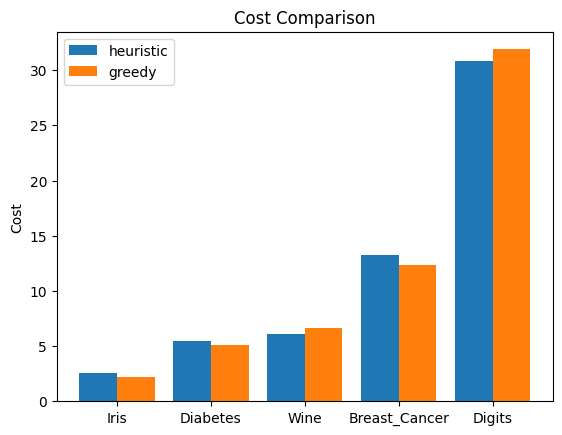

In [184]:
x = range(len(df))

plt.bar([i - 0.2 for i in x], df["h_cost"], width=0.4, label="heuristic")
plt.bar([i + 0.2 for i in x], df["g_cost"], width=0.4, label="greedy")

plt.xticks(x, df["Dataset"])
plt.title("Cost Comparison")
plt.ylabel("Cost")
plt.legend()
plt.savefig("Cost_comparison.png", dpi=300)
plt.show()

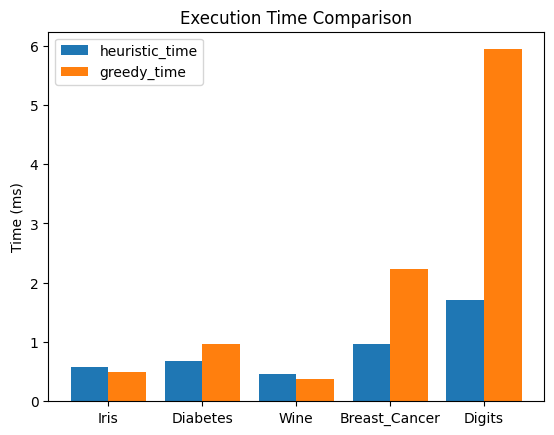

In [185]:
x = range(len(df))

plt.bar([i - 0.2 for i in x], df["h_time"], width=0.4, label="heuristic_time")
plt.bar( [i + 0.2 for i in x], df["g_time"], width=0.4, label="greedy_time")

plt.xticks(x, df["Dataset"])
plt.title("Execution Time Comparison")
plt.ylabel("Time (ms)")
plt.legend()
plt.savefig("time_comparison.png", dpi=300)
plt.show()